Veri Seti Boyutu (Satır, Sütun): (376314, 15)

Sütun Bazlı Eksik Değerler:
 ID                     0
name                   5
category               1
main_category          1
currency               1
deadline               1
goal                   1
launched               1
pledged                1
state                  1
backers                1
country                1
usd pledged         3775
usd_pledged_real       1
usd_goal_real          1
dtype: int64

Sayısal Sütun Özet İstatistikleri:
         usd_goal_real  usd_pledged_real       backers
sum      1.703108e+10      3.411493e+09  3.977822e+07
mean     4.525775e+04      9.065572e+03  1.057051e+02
median   5.500000e+03      6.240000e+02  1.200000e+01

Eğitim Kümesi Boyutu: (301051, 14)
Test Kümesi Boyutu: (75263, 14)


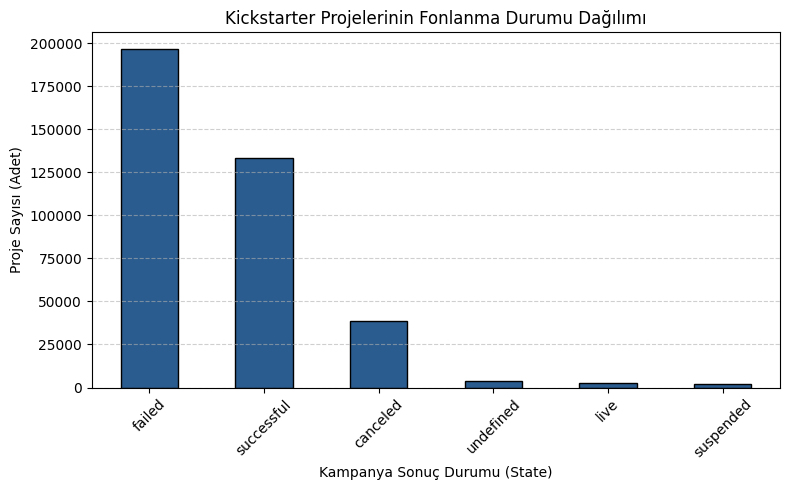

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Veri setini yükle
df = pd.read_csv("ks-projects-201801.csv")

# 2. Genel boyut ve eksik değer kontrolü
print("Veri Seti Boyutu (Satır, Sütun):", df.shape)
print("\nSütun Bazlı Eksik Değerler:\n", df.isna().sum())

# 3. Temel sayısal özet istatistikler (USD)
ozet = df[['usd_goal_real', 'usd_pledged_real', 'backers']].agg(['sum', 'mean', 'median'])
print("\nSayısal Sütun Özet İstatistikleri:\n", ozet)
ozet.to_csv("ozet.csv")

# 4. Veri sızıntısını önlemek için %80 Eğitim / %20 Test bölünmesi
X = df.drop(columns=['state'])
y = df['state']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("\nEğitim Kümesi Boyutu:", X_train.shape)
print("Test Kümesi Boyutu:", X_test.shape)

# 5. Fonlanma Durumu (state) Dağılım Grafiği
plt.figure(figsize=(8, 5))
df['state'].value_counts().plot(kind='bar', color='#2b5c8f', edgecolor='black')
plt.title('Kickstarter Projelerinin Fonlanma Durumu Dağılımı')
plt.xlabel('Kampanya Sonuç Durumu (State)')
plt.ylabel('Proje Sayısı (Adet)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('grafik.png', dpi=300)
plt.show()
